# Área favorável à erva-mate com Random Forest e validação cruzada espacial

Atividade prática de CAP-423. O notebook replica, para a erva-mate (*Ilex paraguariensis*), o fluxo visto em aula com a *Araucaria angustifolia*: classificação binária de área favorável à ocorrência, com Random Forest e validação cruzada espacial. O notebook vai do download das ocorrências até os mapas.

## 0. Ambiente e dados

O notebook foi executado localmente, no Python 3.13 (Miniforge), e não no BDC-Lab. Tudo o que ele lê fica na pasta dele, em `input/`: os 25 rasters preditores e os pontos de solo, copiados do material da aula, e o contorno do Brasil. Os arquivos gerados ficam em `output/`.

**Contorno do Brasil.** O `brazil.gpkg` do curso só está disponível no BDC-Lab. O arquivo de mesmo nome usado aqui vem da [malha `BR_Pais_2025` do IBGE](https://geoftp.ibge.gov.br/organizacao_do_territorio/malhas_territoriais/malhas_municipais/municipio_2025/Brasil/BR_Pais_2025.zip), convertida de SIRGAS 2000 para EPSG:4326. Se o notebook for aberto no BDC-Lab, ele usa o arquivo do curso, e as contagens e o AUC podem mudar, porque o sorteio das pseudoausências depende do contorno.

A troca foi conferida de duas formas:

- As distâncias entre os pontos extremos do contorno (4.378 km norte-sul e 4.326 km leste-oeste) coincidem com as do [mapa de pontos extremos do IBGE](https://geoftp.ibge.gov.br/produtos_educacionais/atlas_educacionais/atlas_geografico_escolar/mapas_do_brasil/mapas_nacionais/fisico/brasil_pontos_extremos_e_fronteiras.pdf) (4.378,4 km e 4.326,6 km).
- 99,84 % dos pixels com dado nos rasters bioclimáticos ficam dentro do contorno.

O contorno inclui lagoas e baías, como a Lagoa dos Patos. Esses pixels não têm dado nos rasters e ficam de fora pela máscara da etapa 2.

In [1]:
%pip install -q pygbif scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [2]:
from pathlib import Path

import numpy as np
import pandas as pd
import geopandas as gpd
import rasterio
import shapely

from pygbif import occurrences as occ
from pyproj import Transformer
from rasterio.transform import rowcol, xy
from shapely.geometry import box

import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_predict, GridSearchCV
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    classification_report,
)
from sklearn.inspection import permutation_importance
from sklearn.neighbors import KNeighborsRegressor

In [3]:
# Os arquivos locais ficam todos na pasta do notebook. O desvio só vale se ele for aberto no BDC-Lab.
BDC_INPUT = Path("/home/jovyan/grupos/pgrad-disciplinas/CAP-423-ciencia-de-dados-geoespaciais/dataset/input")
INPUT_DIR = BDC_INPUT if BDC_INPUT.exists() else Path("input")
BRAZIL_PATH = INPUT_DIR / "brazil.gpkg"

OUTPUT_DIR = Path("output")
OUTPUT_DIR.mkdir(exist_ok=True)

RANDOM_STATE = 123
BUFFER_KM = 20
METRIC_CRS = "EPSG:5880"  # mesmo CRS métrico do notebook 06/06

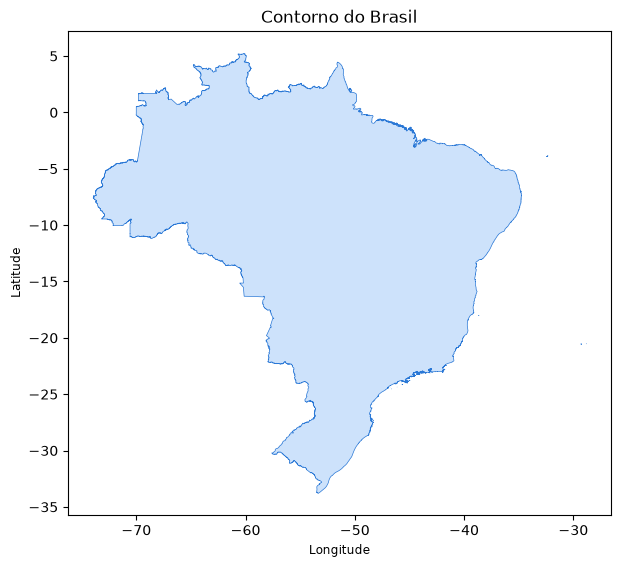

In [4]:
# Conferência visual do contorno usado na limpeza e no sorteio das pseudoausências.
ax = gpd.read_file(BRAZIL_PATH).plot(figsize=(7, 7), facecolor="#cde2fb", edgecolor="#2a78d6", linewidth=0.5)
ax.set(title="Contorno do Brasil", xlabel="Longitude", ylabel="Latitude")
plt.show()

## 1. Ocorrências no GBIF

A busca usa o nome científico, como no enunciado. A busca por `taxonKey` traria 9 registros a mais, com o código `SH1046288.09FU`, que vêm de amostras de solo e não são observações da planta.

`occ.search` não exige credenciais e não gera DOI. O CSV evita repetir o download durante o desenvolvimento. Para baixar de novo, basta apagar a pasta `output/`.

In [5]:
arquivo_bruto = OUTPUT_DIR / "gbif_bruto.csv"

if arquivo_bruto.exists():
    raw = pd.read_csv(arquivo_bruto, low_memory=False)
else:
    registros, offset = [], 0
    while True:
        r = occ.search(
            scientificName="Ilex paraguariensis", country="BR",
            hasCoordinate=True, hasGeospatialIssue=False,
            limit=300, offset=offset,
        )
        registros.extend(r["results"])
        offset += 300
        if r["endOfRecords"]:
            break
    raw = pd.DataFrame(registros)
    raw.to_csv(arquivo_bruto, index=False)

# A ordem fixa torna reprodutível a escolha do registro mantido em cada pixel.
raw = raw.sort_values("key").reset_index(drop=True)
print("Registros baixados:", len(raw))

Registros baixados: 1599


## 2. Preditores e máscara de pixels válidos

Os preditores são os da aula: bio1 a bio19, elevation, slope, HAND, TPI_11x11, NTSI e Mean_curvature. A lista é fixa para não capturar outros `.tif` da pasta e para manter a ordem das colunas entre sistemas operacionais.

Um pixel é válido quando tem dado em todos os preditores. HAND, NTSI e slope não têm dado em parte do litoral e da foz do Amazonas, então essas áreas ficam sem amostras e em branco nos mapas.

In [6]:
PREDITORES = [f"bio{i}" for i in range(1, 20)] + [
    "elevation", "slope", "HAND", "TPI_11x11", "NTSI", "Mean_curvature",
]
raster_files = [INPUT_DIR / f"{nome}.tif" for nome in PREDITORES]

# Pixel válido = dado presente em todos os preditores.
valid = None
for path in raster_files:
    with rasterio.open(path) as src:
        arr = src.read(1)
        ok = np.isfinite(arr)
        if src.nodata is not None:
            ok &= arr != src.nodata
        valid = ok if valid is None else valid & ok

with rasterio.open(raster_files[0]) as ref:
    transform, perfil = ref.transform, ref.profile.copy()

print(f"Pixels válidos: {valid.sum():,} de {valid.size:,}")

Pixels válidos: 10,120,871 de 22,024,128


### Solo

O enunciado inclui dados de solo, mas os 25 rasters da aula não têm essas variáveis, e o material local só as traz como pontos (`c3_soildata_psd_modeling_meters_0_50cm.gpkg`). Por isso, areia, silte e argila são interpoladas com o KNN da aula (`05/feature-engineering/knn-interpolation.ipynb`), com duas diferenças:

- A grade é a dos preditores, não uma de 10 km.
- Não há máscara de 100 km, porque só 3,8 % dos pixels válidos estão além dessa distância (máximo de 199 km) e a máscara abriria buracos no mapa.

In [7]:
soil = gpd.read_file(INPUT_DIR / "c3_soildata_psd_modeling_meters_0_50cm.gpkg")
soil = soil[soil["esqueleto"] < 1000]  # mesma regra de 05/01_EDA
FRACOES = ["areia", "silte", "argila"]

knn = KNeighborsRegressor(n_neighbors=10, weights="distance", n_jobs=-1)
knn.fit(np.column_stack([soil.geometry.x, soil.geometry.y]), soil[FRACOES].to_numpy())

linhas_v, colunas_v = np.nonzero(valid)
lons, lats = xy(transform, linhas_v, colunas_v)
xm, ym = Transformer.from_crs("EPSG:4326", METRIC_CRS, always_xy=True).transform(
    np.asarray(lons), np.asarray(lats)
)
pixels = np.column_stack([xm, ym])
pred = np.vstack([
    knn.predict(pixels[i:i + 1_000_000]) for i in range(0, len(pixels), 1_000_000)
])

perfil.update(count=1, dtype="float32", nodata=np.nan, compress="deflate", predictor=3)
for j, nome in enumerate(FRACOES):
    grade = np.full(valid.shape, np.nan, dtype="float32")
    grade[linhas_v, colunas_v] = pred[:, j]
    with rasterio.open(OUTPUT_DIR / f"{nome}.tif", "w", **perfil) as dst:
        dst.write(grade, 1)

# A lista é refeita, e não acrescida, para a célula poder rodar de novo sem duplicar o solo.
raster_files = [INPUT_DIR / f"{nome}.tif" for nome in PREDITORES]
raster_files += [OUTPUT_DIR / f"{nome}.tif" for nome in FRACOES]
print("Preditores:", len(raster_files))

Preditores: 28


## 3. Limpeza das presenças

O código aplica as regras do enunciado: remove registros sem coordenada, com coordenada (0,0), fora do Brasil ou com coordenada repetida, e mantém uma presença por pixel. A remoção de pixels inválidos acontece aqui, e não na modelagem como na aula, para não quebrar a proporção 1:1.

Os dados da erva-mate também têm erros de coordenada, identificados em 30/10/2026, que justificam regras adicionais:

| Regra | Evidência nos dados | Registros | Pixels |
|---|---|---|---|
| Centro do Brasil | 75 exemplares de 1816 a 1998, sem estado nem município, em (−10,8339; −52,8731), e mais 3 em (−10,7731; −53,0898). Os dois pontos estão a menos de 60 km do centro geométrico do país, o que indica georreferência no nível do país | 78 | 2 |
| Incerteza > 10 km | Inútil com pixel de 1 km. Inclui 53 registros do iNaturalist, com cerca de 30 km | 85 | 76 |
| Longitude trocada | Rio de Contas (BA) com longitude −47,95. Os demais registros do município estão em cerca de −41,9 | 2 | 2 |
| Fora da distribuição | Amazonas (1971) e Sinop/MT (2017), regiões que o [estudo da Embrapa](https://www.alice.cnptia.embrapa.br/alice/bitstream/doc/300244/1/AreaDistribuicao.pdf) não cita | 4 | 3 |
| Grau inteiro | (−14,0003; −50,0004), em Goiás (1966) | 1 | 1 |

Outras escolhas:

- **Incerteza ausente não exclui.** Ela falta em cerca de 94 % dos registros, então exigi-la eliminaria quase toda a base.
- **O Distrito Federal permanece** (5 registros, que viram 3 presenças). O estudo da Embrapa diz que os limites da espécie "são ainda indeterminados", então não há evidência suficiente para excluí-lo.
- **Não sobra presença em Goiás.** A única coordenada no estado é a do ponto de grau inteiro. Outro registro marcado como Rio Verde/GO (1997) tem coordenada no sul de São Paulo (−24,08; −49,21). Ele permanece, porque não dá para saber qual campo está errado e a coordenada cai na área principal da espécie.
- **A *var. sincorensis* permanece** (83 registros, quase todos na Bahia), porque o alvo é a espécie e o GBIF a trata assim. Essa escolha modela a espécie, não apenas a área ervateira clássica.

In [8]:
brazil = gpd.read_file(BRAZIL_PATH).to_crs("EPSG:4326")
brasil = brazil.geometry.union_all()
shapely.prepare(brasil)  # acelera as consultas ponto no polígono


def dentro_do_brasil(g):
    return shapely.contains_xy(brasil, g.geometry.x.to_numpy(), g.geometry.y.to_numpy())


etapas = {"Baixados do GBIF": len(raw)}

pres = raw.dropna(subset=["decimalLatitude", "decimalLongitude"])
pres = pres[~((pres["decimalLatitude"] == 0) & (pres["decimalLongitude"] == 0))]
pres = gpd.GeoDataFrame(
    pres,
    geometry=gpd.points_from_xy(pres["decimalLongitude"], pres["decimalLatitude"]),
    crs="EPSG:4326",
)
etapas["Com coordenada válida, sem (0,0)"] = len(pres)

lat, lon = pres.geometry.y.round(3), pres.geometry.x.round(3)
incerteza = pd.to_numeric(pres["coordinateUncertaintyInMeters"], errors="coerce")
regras = {
    "Centro do Brasil": ((lat == -10.834) & (lon == -52.873)) | ((lat == -10.773) & (lon == -53.090)),
    "Incerteza > 10 km": incerteza > 10_000,
    "Longitude trocada": pres["municipality"].fillna("").str.contains("Rio de Contas") & (lon < -44),
    "Fora da distribuição": (lon < -60) | (lat.between(-12, -11) & lon.between(-56, -55)),
    "Grau inteiro": (lat == -14.0) & (lon == -50.0),
}
print({nome: int(m.sum()) for nome, m in regras.items()})
pres = pres[~np.logical_or.reduce(list(regras.values()))]
etapas["Sem erros de coordenada"] = len(pres)

pres = pres[dentro_do_brasil(pres)]
etapas["Dentro do Brasil"] = len(pres)

pres = pres.drop_duplicates(["decimalLatitude", "decimalLongitude"])
etapas["Coordenadas únicas"] = len(pres)

linhas_p, colunas_p = rowcol(transform, pres.geometry.x.to_numpy(), pres.geometry.y.to_numpy())
pres["row"], pres["col"] = np.asarray(linhas_p), np.asarray(colunas_p)
pres = pres[valid[pres["row"], pres["col"]]]
etapas["Em pixel válido"] = len(pres)

pres = pres.drop_duplicates(["row", "col"])
etapas["Uma presença por pixel"] = len(pres)

display(pd.Series(etapas, name="Registros"))

{'Centro do Brasil': 78, 'Incerteza > 10 km': 85, 'Longitude trocada': 2, 'Fora da distribuição': 4, 'Grau inteiro': 1}


Baixados do GBIF                    1599
Com coordenada válida, sem (0,0)    1599
Sem erros de coordenada             1429
Dentro do Brasil                    1424
Coordenadas únicas                   807
Em pixel válido                      779
Uma presença por pixel               571
Name: Registros, dtype: int64

## 4. Pseudoausências

O notebook `06/06` sorteia pontos no polígono do Brasil sem olhar os rasters. Aqui o sorteio é feito entre os pixels válidos, como pede o enunciado, e o restante segue a aula: mesmo CRS métrico e mesma estrutura final do GeoPackage (EPSG:4326, colunas `id`, `presence` e `geometry`).

- **Região:** todo o Brasil, como na aula.
- **Distância:** ao menos 20 km das presenças, o limite superior do enunciado, porque muitas coordenadas de herbário são imprecisas.
- **Pixels:** o sorteio é sem reposição e o ponto fica no centro do pixel, então nenhum pixel se repete nem coincide com uma presença.
- **Proporção e semente:** 1:1, com `RANDOM_STATE = 123`.

In [9]:
n_presencas = len(pres)
rng = np.random.default_rng(RANDOM_STATE)

# Sorteia pixels válidos a mais e descarta os que violam as restrições.
sorteados = rng.choice(np.flatnonzero(valid), size=n_presencas * 20, replace=False)
xs, ys = xy(transform, *np.unravel_index(sorteados, valid.shape))
candidatos = gpd.GeoDataFrame(geometry=gpd.points_from_xy(xs, ys), crs="EPSG:4326")
candidatos = candidatos[dentro_do_brasil(candidatos)].reset_index(drop=True)

perto, _ = pres.to_crs(METRIC_CRS).sindex.query(
    candidatos.to_crs(METRIC_CRS).geometry, predicate="dwithin", distance=BUFFER_KM * 1000
)
pseudo = candidatos.drop(index=np.unique(perto)).iloc[:n_presencas]

if len(pseudo) != n_presencas:
    raise RuntimeError("Candidatos insuficientes: aumente o fator de sorteio.")

samples = pd.concat(
    [pres[["geometry"]].assign(presence=1), pseudo[["geometry"]].assign(presence=0)],
    ignore_index=True,
)
samples = gpd.GeoDataFrame(samples, geometry="geometry", crs="EPSG:4326")
samples["id"] = np.arange(1, len(samples) + 1)
samples = samples[["id", "presence", "geometry"]]

samples_path = OUTPUT_DIR / "ErvaMate_pseudo_absence.gpkg"
samples.to_file(samples_path, driver="GPKG")
print(samples["presence"].value_counts())

INFO:Created 1,142 records


presence
1    571
0    571
Name: count, dtype: int64


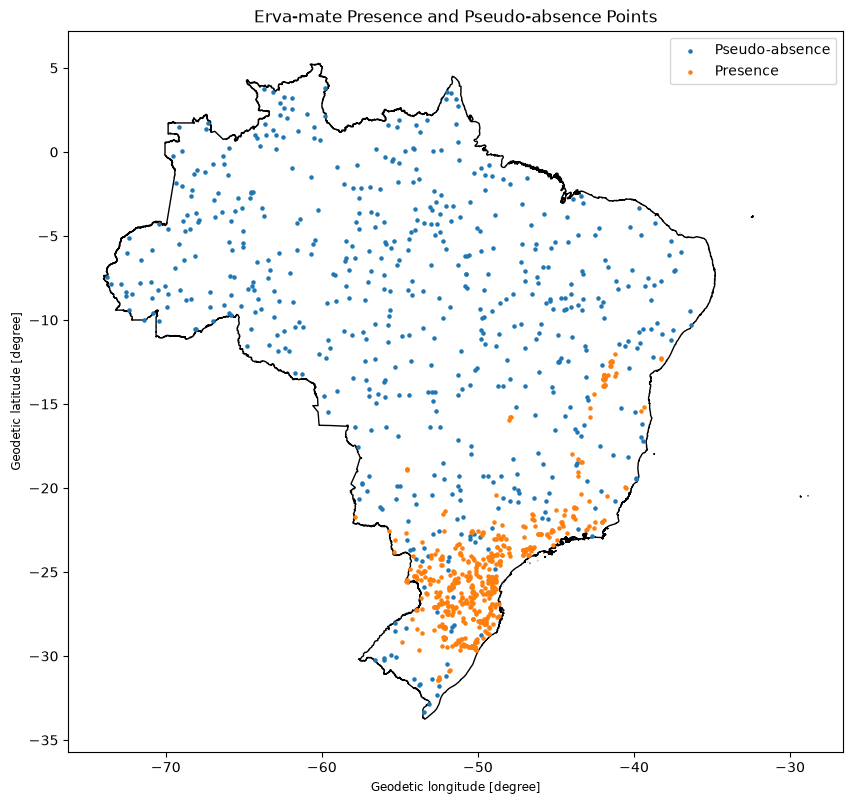

In [10]:
# ============================================================
# VISUAL CHECK
# ============================================================

# Read the combined presence/pseudo-absence dataset.
samples = gpd.read_file(samples_path)

# Reproject Brazil boundary to the same CRS.
brazil_plot = brazil.to_crs(samples.crs)

# Separate classes only for visualization.
presence_plot = samples[samples["presence"] == 1]
pseudo_absence_plot = samples[samples["presence"] == 0]

# Plot Brazil boundary.
ax = brazil_plot.plot(
    figsize=(10, 10),
    facecolor="none",
    edgecolor="black"
)

# Plot pseudo-absence points.
pseudo_absence_plot.plot(
    ax=ax,
    markersize=5,
    label="Pseudo-absence"
)

# Plot presence points.
presence_plot.plot(
    ax=ax,
    markersize=5,
    label="Presence"
)

plt.legend()
plt.title("Erva-mate Presence and Pseudo-absence Points")
plt.show()

## 5. Modelagem

O fluxo segue o notebook `06/08` da aula: blocos de 2° × 2°, divisão de cerca de 80/20 por blocos, validação cruzada espacial com 10 folds, ajuste do Random Forest por ROC AUC e métricas no teste independente. As células são as da aula, com duas trocas: a leitura dos dados (seções 1 e 2 do `06/08`) e a alocação dos folds (seção 7).

### 5.1 Amostras e preditores

O GeoPackage da etapa 4 entra no lugar do arquivo da aula, e a lista de preditores vem da etapa 2.

In [11]:
samples = gpd.read_file(samples_path)
samples["presence"] = samples["presence"].astype(int)
raster_names = [f.stem for f in raster_files]

### 5.2 Valores dos rasters nas amostras

As amostras ficam no CRS dos rasters, que é geográfico, porque os blocos são definidos em graus.

In [12]:
# Check sample and raster CRS.
with rasterio.open(raster_files[0]) as src:
    raster_crs = src.crs

print("Sample CRS:", samples.crs)
print("Raster CRS:", raster_crs)

if samples.crs != raster_crs:
    samples = samples.to_crs(raster_crs)

if not samples.crs.is_geographic:
    raise ValueError(
        "The sample/raster CRS must be geographic to create 2° x 2° blocks."
    )

Sample CRS: EPSG:4326
Raster CRS: EPSG:4326


In [13]:
# Extract predictor values at sample locations.
coords = [(geom.x, geom.y) for geom in samples.geometry]

for raster_path, raster_name in zip(raster_files, raster_names):
    with rasterio.open(raster_path) as src:
        values = np.array([v[0] for v in src.sample(coords)], dtype="float64")

        if src.nodata is not None:
            values[values == src.nodata] = np.nan

        samples[raster_name] = values

display(samples.head())

,id,presence,geometry,bio1,bio2,bio3,bio4,bio5,bio6,bio7,...,bio19,elevation,slope,HAND,TPI_11x11,NTSI,Mean_curvature,areia,silte,argila
0,1,1,POINT (-54.8689 -29.1833),18.716667,11.150001,51.382488,399.979156,30.000000,8.3,21.700001,...,440.0,392.0,0.946288,151.000000,10.727273,-0.001653,0.000007,247.967133,371.030151,381.002716
1,2,1,POINT (-50.20239 -29.1812),14.866667,9.533334,53.558056,304.655792,23.799999,6.0,17.799999,...,487.0,1008.0,0.396489,190.000977,34.892563,-0.000952,0.000002,319.685913,262.957336,417.356750
2,3,1,POINT (-50.40473 -25.86476),17.049999,11.866667,56.778309,327.878876,27.100000,6.2,20.900002,...,307.0,796.0,0.775087,35.002991,3.082645,-0.005147,0.000016,55.431572,315.732086,628.836365
3,4,1,POINT (-50.38521 -25.77286),17.137501,11.875000,57.367149,323.834442,27.000000,6.3,20.700001,...,290.0,804.0,0.523729,43.000000,-28.628099,-0.004032,-0.000013,66.787529,299.402893,633.809570
4,5,1,POINT (-53.33333 -26.25),17.312500,13.191667,62.224838,296.365295,27.700001,6.5,21.200001,...,471.0,891.0,2.444429,435.001007,80.776863,-0.001230,0.000037,67.494003,228.103073,704.402893


### 5.3 Base de modelagem

Só ficam a resposta e os preditores. Como a etapa 4 usa apenas pixels válidos, nenhuma amostra deve ser perdida aqui.

In [14]:
# Keep only the response and raster predictor columns.
model_columns = ["presence"] + raster_names
samples_df = samples[model_columns].copy()

print("Samples before removing NA:", len(samples_df))

# Keep complete observations only.
complete_idx = samples_df.notna().all(axis=1)

samples_df = samples_df.loc[complete_idx].reset_index(drop=True)
samples_model = samples.loc[complete_idx].reset_index(drop=True)

# Add a permanent observation ID.
samples_model["obs_id"] = np.arange(len(samples_model))

print("Complete samples:", len(samples_df))
print()
print("Class distribution after removing NA:")
print(samples_df["presence"].value_counts().sort_index())

display(samples_df.head())

Samples before removing NA: 1142
Complete samples: 1142

Class distribution after removing NA:
presence
0    571
1    571
Name: count, dtype: int64


,presence,bio1,bio2,bio3,bio4,bio5,bio6,bio7,bio8,bio9,...,bio19,elevation,slope,HAND,TPI_11x11,NTSI,Mean_curvature,areia,silte,argila
0,1,18.716667,11.150001,51.382488,399.979156,30.000000,8.3,21.700001,15.933333,22.883333,...,440.0,392.0,0.946288,151.000000,10.727273,-0.001653,0.000007,247.967133,371.030151,381.002716
1,1,14.866667,9.533334,53.558056,304.655792,23.799999,6.0,17.799999,18.683334,15.950000,...,487.0,1008.0,0.396489,190.000977,34.892563,-0.000952,0.000002,319.685913,262.957336,417.356750
2,1,17.049999,11.866667,56.778309,327.878876,27.100000,6.2,20.900002,20.916668,13.049999,...,307.0,796.0,0.775087,35.002991,3.082645,-0.005147,0.000016,55.431572,315.732086,628.836365
3,1,17.137501,11.875000,57.367149,323.834442,27.000000,6.3,20.700001,20.916666,13.150000,...,290.0,804.0,0.523729,43.000000,-28.628099,-0.004032,-0.000013,66.787529,299.402893,633.809570
4,1,17.312500,13.191667,62.224838,296.365295,27.700001,6.5,21.200001,20.816668,17.166666,...,471.0,891.0,2.444429,435.001007,80.776863,-0.001230,0.000037,67.494003,228.103073,704.402893


### 5.4 Blocos de 2° × 2°

Cada amostra pertence a um bloco fixo. As divisões usam blocos inteiros, não pontos.

In [15]:
# ============================================================
# CREATE SPATIAL BLOCKS
# ============================================================

block_size = 2.0

samples_model["longitude_cv"] = samples_model.geometry.x
samples_model["latitude_cv"] = samples_model.geometry.y

# Anchor the grid at multiples of 2 degrees.
origin_lon = (
    np.floor(samples_model["longitude_cv"].min() / block_size)
    * block_size
)
origin_lat = (
    np.floor(samples_model["latitude_cv"].min() / block_size)
    * block_size
)

samples_model["block_col"] = np.floor(
    (samples_model["longitude_cv"] - origin_lon) / block_size
).astype(int)

samples_model["block_row"] = np.floor(
    (samples_model["latitude_cv"] - origin_lat) / block_size
).astype(int)

samples_model["block_id"] = (
    "B_"
    + samples_model["block_col"].astype(str)
    + "_"
    + samples_model["block_row"].astype(str)
)

print("Grid origin:", origin_lon, origin_lat)
print("Total samples:", len(samples_model))
print("Occupied blocks:", samples_model["block_id"].nunique())

Grid origin: -74.0 -34.0
Total samples: 1142
Occupied blocks: 187


In [16]:
# Create occupied block polygons.
block_index = (
    samples_model[["block_id", "block_col", "block_row"]]
    .drop_duplicates()
    .reset_index(drop=True)
)

block_index["geometry"] = [
    box(
        origin_lon + col * block_size,
        origin_lat + row * block_size,
        origin_lon + (col + 1) * block_size,
        origin_lat + (row + 1) * block_size,
    )
    for col, row in zip(
        block_index["block_col"],
        block_index["block_row"]
    )
]

blocks_gdf = gpd.GeoDataFrame(
    block_index,
    geometry="geometry",
    crs=samples_model.crs
)

### 5.5 Divisão de cerca de 80/20 por blocos

Cada bloco vai inteiro para o treino ou para o teste. Como os blocos têm tamanhos diferentes, a proporção é aproximada. A busca também favorece um teste com prevalência próxima à do conjunto completo.

In [17]:
# ============================================================
# SPATIAL TRAIN / TEST SPLIT: ~80/20
# ============================================================

test_fraction = 0.20
k_folds = 10
random_state = 123
n_candidates = 2000

# Block-level sample and class counts.
block_stats = (
    samples_model
    .assign(presence=samples_df["presence"].to_numpy())
    .groupby("block_id")
    .agg(
        n=("presence", "size"),
        n_presence=("presence", "sum")
    )
    .reset_index()
)

if len(block_stats) <= k_folds:
    raise ValueError(
        f"At least {k_folds + 1} occupied blocks are required."
    )

total_n = len(samples_model)
overall_prevalence = samples_df["presence"].mean()
target_n_test = total_n * test_fraction

rng = np.random.RandomState(random_state)
best_score = np.inf
best_test_blocks = None

# Search reproducibly for a block split close to 20% of samples
# while retaining both classes in train and test.
for _ in range(n_candidates):
    shuffled = block_stats.iloc[
        rng.permutation(len(block_stats))
    ].reset_index(drop=True)

    max_test_blocks = len(shuffled) - k_folds
    cum_n = shuffled["n"].cumsum().to_numpy()
    cum_pos = shuffled["n_presence"].cumsum().to_numpy()

    for cut in range(1, max_test_blocks + 1):
        n_test = cum_n[cut - 1]
        pos_test = cum_pos[cut - 1]
        neg_test = n_test - pos_test

        n_train = total_n - n_test
        pos_train = samples_df["presence"].sum() - pos_test
        neg_train = n_train - pos_train

        # Both classes must be present in both partitions.
        if min(pos_test, neg_test, pos_train, neg_train) == 0:
            continue

        test_prevalence = pos_test / n_test

        score = (
            abs(n_test / total_n - test_fraction)
            + abs(test_prevalence - overall_prevalence)
        )

        if score < best_score:
            best_score = score
            best_test_blocks = set(
                shuffled.loc[: cut - 1, "block_id"]
            )

if best_test_blocks is None:
    raise RuntimeError(
        "A valid 80/20 spatial split with both classes was not found."
    )

test_blocks = best_test_blocks
train_blocks = set(block_stats["block_id"]) - test_blocks

if train_blocks & test_blocks:
    raise RuntimeError("Spatial leakage detected between train and test blocks.")

samples_model["dataset"] = np.where(
    samples_model["block_id"].isin(test_blocks),
    "Independent test",
    "Training"
)

split_table = pd.crosstab(
    samples_model["dataset"],
    samples_df["presence"],
    margins=True
)

print(split_table)
print()
print("Training blocks:", len(train_blocks))
print("Test blocks:", len(test_blocks))
print(
    "Actual test sample proportion:",
    round((samples_model["dataset"] == "Independent test").mean(), 3)
)

presence            0    1   All
dataset                         
Independent test  114  114   228
Training          457  457   914
All               571  571  1142

Training blocks: 147
Test blocks: 40
Actual test sample proportion: 0.2


### 5.6 Folds espaciais (troca em relação à aula)

A seção 7 do `06/08` falha com 10 folds. A pontuação dela favorece o fold mais próximo da meta de tamanho, então blocos pequenos continuam entrando em folds já cheios e os folds 7 a 10 ficam vazios. O erro aparece depois, na seção 9, como `Fold 7 validation contains only one class`, o mesmo salvo no notebook da aula.

Aqui, a `StratifiedGroupKFold` mantém cada bloco inteiro em um único fold e equilibra as classes, que é o objetivo declarado na seção 7.

In [18]:
from sklearn.model_selection import StratifiedGroupKFold

train_ids = samples_model["dataset"] == "Training"
blocks_train = samples_model.loc[train_ids, "block_id"].to_numpy()
y_folds = samples_df.loc[train_ids, "presence"].to_numpy()

sgkf = StratifiedGroupKFold(n_splits=k_folds, shuffle=True, random_state=random_state)
fold_lookup = {}
for fold, (_, val_idx) in enumerate(sgkf.split(blocks_train, y_folds, groups=blocks_train), start=1):
    fold_lookup.update(dict.fromkeys(blocks_train[val_idx], fold))

samples_model["fold"] = samples_model["block_id"].map(fold_lookup)

### 5.7 Diagnóstico dos folds

As tabelas e os mapas conferem amostras, blocos e classes em cada fold de validação.

In [19]:
# Summarize class composition of validation folds.
training_summary = samples_model.loc[
    samples_model["dataset"] == "Training",
    ["block_id", "fold"]
].copy()
training_summary["presence"] = samples_df.loc[
    samples_model["dataset"] == "Training",
    "presence"
].to_numpy()

fold_summary = (
    training_summary
    .groupby("fold")
    .agg(
        Validation_samples=("presence", "size"),
        Validation_blocks=("block_id", "nunique"),
        Presence=("presence", "sum")
    )
    .reset_index()
)

fold_summary["Pseudo_absence"] = (
    fold_summary["Validation_samples"] - fold_summary["Presence"]
)
fold_summary["fold"] = fold_summary["fold"].astype(int)

# Every validation fold should contain both classes.
invalid_folds = fold_summary[
    (fold_summary["Presence"] == 0)
    | (fold_summary["Pseudo_absence"] == 0)
]

if not invalid_folds.empty:
    raise ValueError(
        "At least one spatial fold contains only one class. "
        "Reduce k_folds, change block_size, or revise the block assignment."
    )

display(fold_summary)

,fold,Validation_samples,Validation_blocks,Presence,Pseudo_absence
0,1,89,14,45,44
1,2,94,13,50,44
2,3,94,15,44,50
3,4,114,14,70,44
4,5,89,13,45,44
5,6,86,14,40,46
6,7,87,17,40,47
7,8,85,13,40,45
8,9,90,16,44,46
9,10,86,18,39,47


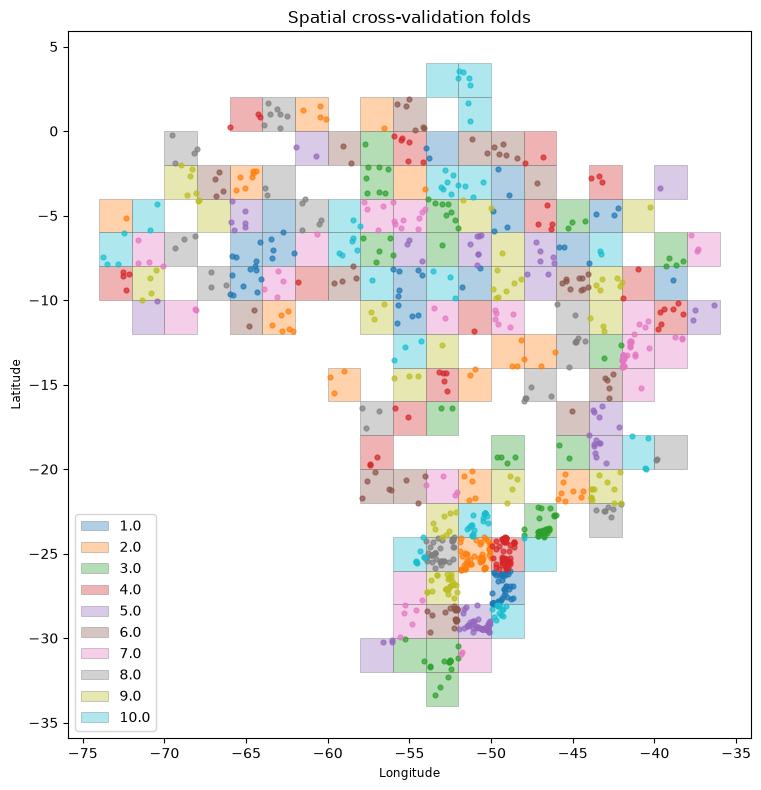

In [20]:
# Add partition/fold information to block polygons.
block_info = (
    samples_model[["block_id", "dataset", "fold"]]
    .drop_duplicates("block_id")
)

blocks_plot = blocks_gdf.merge(
    block_info,
    on="block_id",
    how="left"
)

# Plot spatial training folds.
fig, ax = plt.subplots(figsize=(10, 8))

training_blocks_plot = blocks_plot[
    blocks_plot["dataset"] == "Training"
].copy()

training_points_plot = samples_model[
    samples_model["dataset"] == "Training"
].copy()

training_blocks_plot.plot(
    ax=ax,
    column="fold",
    categorical=True,
    alpha=0.35,
    edgecolor="0.35",
    linewidth=0.6,
    legend=True,
)

training_points_plot.plot(
    ax=ax,
    column="fold",
    categorical=True,
    markersize=12,
    alpha=0.7,
)

ax.set_title("Spatial cross-validation folds")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
plt.tight_layout()
plt.show()

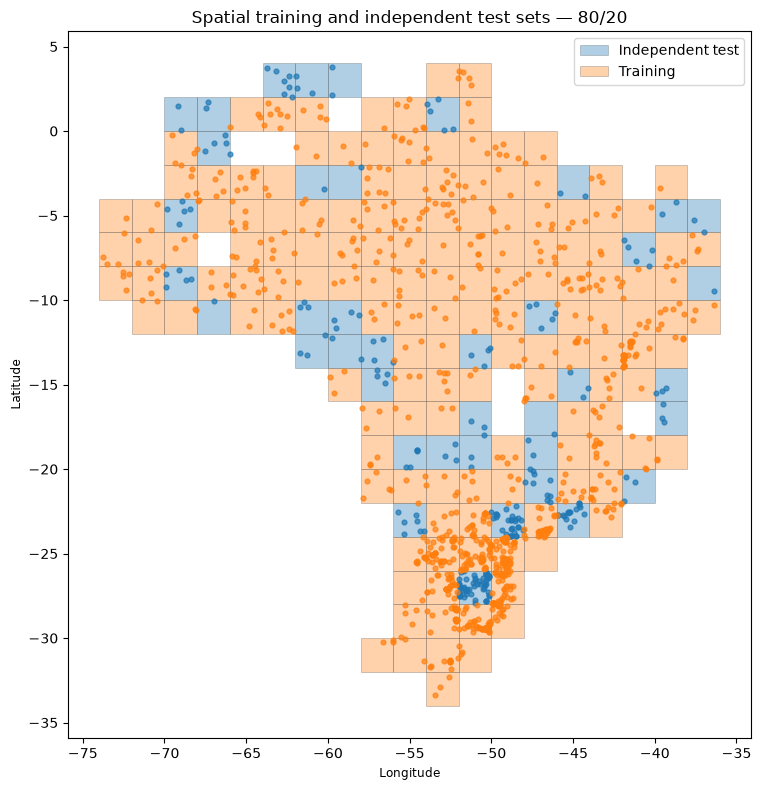

In [21]:
# Plot spatial training and independent test sets.
fig, ax = plt.subplots(figsize=(10, 8))

blocks_plot.plot(
    ax=ax,
    column="dataset",
    categorical=True,
    alpha=0.35,
    edgecolor="0.35",
    linewidth=0.6,
    legend=True,
)

samples_model.plot(
    ax=ax,
    column="dataset",
    categorical=True,
    markersize=12,
    alpha=0.7,
)

ax.set_title("Spatial training and independent test sets — 80/20")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
plt.tight_layout()
plt.show()

### 5.8 Índices da validação cruzada

Os índices de cada fold são passados explicitamente ao scikit-learn, com a checagem de que nenhum bloco aparece no treino e na validação ao mesmo tempo.

In [22]:
# Create predictor matrix and response vector.
X = samples_df.drop(columns="presence")
y = samples_df["presence"].astype(int)

train_mask = (
    samples_model["dataset"] == "Training"
).to_numpy()

test_mask = (
    samples_model["dataset"] == "Independent test"
).to_numpy()

X_train = X.loc[train_mask].reset_index(drop=True)
X_test = X.loc[test_mask].reset_index(drop=True)

y_train = y.loc[train_mask].reset_index(drop=True)
y_test = y.loc[test_mask].reset_index(drop=True)

train_spatial = samples_model.loc[train_mask].reset_index(drop=True)
test_spatial = samples_model.loc[test_mask].reset_index(drop=True)

print("Training samples:", len(X_train))
print("Independent test samples:", len(X_test))
print()
print("Training class distribution:")
print(y_train.value_counts().sort_index())
print()
print("Test class distribution:")
print(y_test.value_counts().sort_index())

Training samples: 914
Independent test samples: 228

Training class distribution:
presence
0    457
1    457
Name: count, dtype: int64

Test class distribution:
presence
0    114
1    114
Name: count, dtype: int64


In [23]:
# ============================================================
# BUILD SCIKIT-LEARN SPATIAL CV INDICES
# ============================================================

training_fold_id = train_spatial["fold"].astype(int).to_numpy()
spatial_cv = []

for fold in range(1, k_folds + 1):
    validation_idx = np.flatnonzero(training_fold_id == fold)
    train_idx = np.flatnonzero(training_fold_id != fold)

    # ROC AUC requires both classes in training and validation.
    if y_train.iloc[validation_idx].nunique() < 2:
        raise ValueError(f"Fold {fold} validation contains only one class.")
    if y_train.iloc[train_idx].nunique() < 2:
        raise ValueError(f"Fold {fold} training contains only one class.")

    spatial_cv.append((train_idx, validation_idx))

cv_index_summary = pd.DataFrame({
    "Fold": np.arange(1, k_folds + 1),
    "Training samples": [len(a) for a, _ in spatial_cv],
    "Validation samples": [len(b) for _, b in spatial_cv],
})

display(cv_index_summary)

,Fold,Training samples,Validation samples
0,1,825,89
1,2,820,94
2,3,820,94
3,4,800,114
4,5,825,89
5,6,828,86
6,7,827,87
7,8,829,85
8,9,824,90
9,10,828,86


In [24]:
# Check block leakage within every fold.
for fold, (train_idx, validation_idx) in enumerate(spatial_cv, start=1):
    train_blocks_fold = set(train_spatial.loc[train_idx, "block_id"])
    validation_blocks_fold = set(train_spatial.loc[validation_idx, "block_id"])

    if train_blocks_fold & validation_blocks_fold:
        raise RuntimeError(f"Spatial leakage detected in Fold {fold}.")

print(
    "Spatial leakage check passed: "
    "no block is shared between training and validation."
)

Spatial leakage check passed: no block is shared between training and validation.


### 5.9 Ajuste do Random Forest

Os hiperparâmetros são escolhidos nos folds espaciais pelo ROC AUC, que avalia a ordenação das probabilidades sem depender de um limiar.

In [25]:
# Define the Random Forest classifier.
model_rf = RandomForestClassifier(
    n_estimators=300,
    random_state=random_state,
    n_jobs=-1
)

# Small tuning grid for classroom use.
param_grid = {
    "max_features": ["sqrt", 0.5, 1.0],
    "min_samples_leaf": [1, 3, 5]
}

# Tune with predefined spatial folds.
grid_search = GridSearchCV(
    estimator=model_rf,
    param_grid=param_grid,
    scoring="roc_auc",
    cv=spatial_cv,
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train, y_train)

# Best model refitted on all training samples.
model_rf = grid_search.best_estimator_

print("Best parameters:")
print(grid_search.best_params_)

print()
print("Best mean spatial CV ROC AUC:")
print(round(grid_search.best_score_, 3))

Fitting 10 folds for each of 9 candidates, totalling 90 fits
Best parameters:
{'max_features': 'sqrt', 'min_samples_leaf': 5}

Best mean spatial CV ROC AUC:
0.974


### 5.10 Desempenho na validação cruzada

As probabilidades fora do fold são convertidas em classes com o limiar de 0,50.

In [26]:
# Generate spatial out-of-fold probabilities.
prob_cv_all = cross_val_predict(
    model_rf,
    X_train,
    y_train,
    cv=spatial_cv,
    method="predict_proba",
    n_jobs=-1
)

# Locate the probability column for class 1.
class_1_idx = list(model_rf.classes_).index(1)
prob_cv = prob_cv_all[:, class_1_idx]

classification_threshold = 0.50
pred_cv = (prob_cv >= classification_threshold).astype("uint8")

metrics_cv = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Balanced accuracy",
        "Precision",
        "Recall",
        "F1",
        "ROC AUC"
    ],
    "Value": [
        accuracy_score(y_train, pred_cv),
        balanced_accuracy_score(y_train, pred_cv),
        precision_score(y_train, pred_cv, zero_division=0),
        recall_score(y_train, pred_cv, zero_division=0),
        f1_score(y_train, pred_cv, zero_division=0),
        roc_auc_score(y_train, prob_cv),
    ]
})

display(metrics_cv.round(3))

,Metric,Value
0,Accuracy,0.912
1,Balanced accuracy,0.912
2,Precision,0.899
3,Recall,0.930
4,F1,0.914
5,ROC AUC,0.966


### 5.11 Importância por permutação

É calculada no teste independente e mede quanto o ROC AUC cai quando a informação de um preditor é destruída.

In [27]:
# Calculate permutation importance on independent spatial test data.
perm_importance = permutation_importance(
    model_rf,
    X_test,
    y_test,
    scoring="roc_auc",
    n_repeats=10,
    random_state=random_state,
    n_jobs=-1
)

importance_df = pd.DataFrame({
    "Variable": X_test.columns,
    "Importance": perm_importance.importances_mean
}).sort_values("Importance", ascending=False)

display(importance_df.head(20))

,Variable,Importance
0,bio1,0.011534
10,bio11,0.008503
8,bio9,0.007679
4,bio5,0.006056
9,bio10,0.004978
2,bio3,0.003209
3,bio4,0.002408
5,bio6,0.002285
17,bio18,0.002054
7,bio8,0.001816


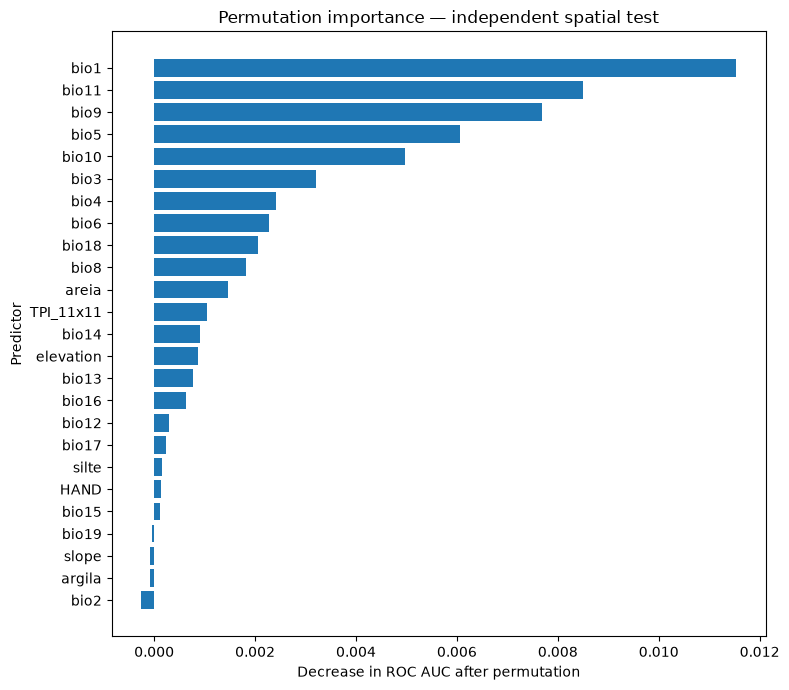

In [28]:
# Plot the most important predictors.
top_imp = importance_df.head(25).sort_values("Importance")

plt.figure(figsize=(8, 7))
plt.barh(top_imp["Variable"], top_imp["Importance"])
plt.xlabel("Decrease in ROC AUC after permutation")
plt.ylabel("Predictor")
plt.title("Permutation importance — independent spatial test")
plt.tight_layout()
plt.show()

### 5.12 Predição no teste independente

O teste reúne blocos inteiros que não participaram do ajuste nem da escolha dos hiperparâmetros.

In [29]:
# Predict probability of presence in unseen spatial blocks.
prob_test = model_rf.predict_proba(X_test)[:, class_1_idx]

# Convert probability to binary prediction.
pred_test = (
    prob_test >= classification_threshold
).astype("uint8")

### 5.13 Métricas do teste independente

É a principal estimativa de desempenho em regiões não vistas.

In [30]:
# Calculate independent spatial-test metrics.
metrics_test = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Balanced accuracy",
        "Precision",
        "Recall",
        "F1",
        "ROC AUC"
    ],
    "Value": [
        accuracy_score(y_test, pred_test),
        balanced_accuracy_score(y_test, pred_test),
        precision_score(y_test, pred_test, zero_division=0),
        recall_score(y_test, pred_test, zero_division=0),
        f1_score(y_test, pred_test, zero_division=0),
        roc_auc_score(y_test, prob_test),
    ]
})

display(metrics_test.round(3))

print("Classification report:")
print(
    classification_report(
        y_test,
        pred_test,
        target_names=["Pseudo-absence", "Presence"],
        zero_division=0
    )
)

,Metric,Value
0,Accuracy,0.943
1,Balanced accuracy,0.943
2,Precision,0.917
3,Recall,0.974
4,F1,0.945
5,ROC AUC,0.982


Classification report:
                precision    recall  f1-score   support

Pseudo-absence       0.97      0.91      0.94       114
      Presence       0.92      0.97      0.94       114

      accuracy                           0.94       228
     macro avg       0.94      0.94      0.94       228
  weighted avg       0.94      0.94      0.94       228



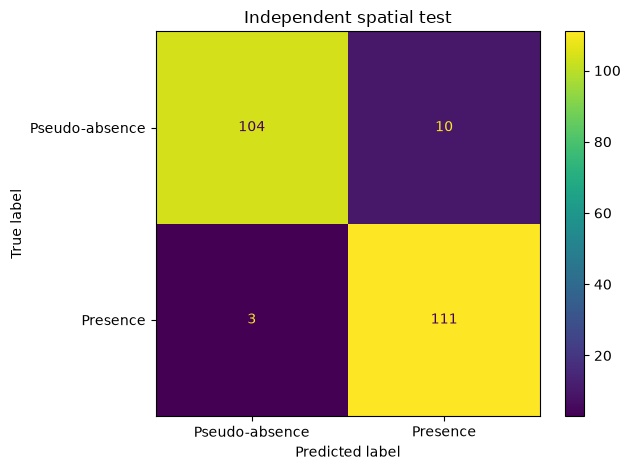

In [31]:
# Display the confusion matrix.
cm = confusion_matrix(y_test, pred_test, labels=[0, 1])

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Pseudo-absence", "Presence"]
).plot(values_format="d")

plt.title("Independent spatial test")
plt.tight_layout()
plt.show()

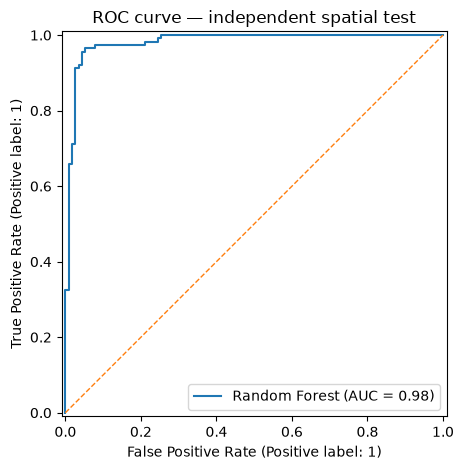

In [32]:
# Display the ROC curve for the independent spatial test.
RocCurveDisplay.from_predictions(
    y_test,
    prob_test,
    name="Random Forest"
)

plt.plot([0, 1], [0, 1], linestyle="--", linewidth=1)
plt.title("ROC curve — independent spatial test")
plt.tight_layout()
plt.show()

### 5.14 Comparação com a latitude

O AUC obtido só com a latitude mostra quanto da separação entre as classes se deve à geografia.

In [33]:
auc_latitude = roc_auc_score(y_test, -test_spatial["latitude_cv"])
print("AUC do modelo:", round(roc_auc_score(y_test, prob_test), 3))
print("AUC só com a latitude:", round(auc_latitude, 3))
print("Blocos de teste com presença:", test_spatial.loc[y_test == 1, "block_id"].nunique())

AUC do modelo: 0.982
AUC só com a latitude: 0.968
Blocos de teste com presença: 8


### Como interpretar

Os testes citados aqui usaram o mesmo fluxo, mas foram feitos fora deste notebook, em 30/10/2026.

- **AUC alto não basta.** As presenças estão no Sul e no Sudeste, e as pseudoausências cobrem o país, então a latitude sozinha já separa boa parte das classes. O AUC do modelo deve ser lido junto com a comparação acima.
- **O AUC depende da amostra.** As presenças do teste ficam em poucos blocos, como mostra a saída acima. O AUC variou de 0,892 a 0,983 trocando a semente da divisão e de 0,929 a 0,994 trocando a das pseudoausências. A semente é a mesma da aula (123) e não foi escolhida pelo resultado.
- **Importância perto de zero não significa variável inútil.** Há 20 pares de preditores, entre 378, com correlação de Spearman acima de 0,9. Ao permutar uma variável, as correlacionadas compensam a perda.
- **O solo teve efeito pequeno.** O AUC do teste foi de 0,975 sem solo e 0,982 com solo, uma diferença menor que a variação entre sementes. Isso não prova que o solo seja irrelevante: KNN sobre pontos esparsos é uma camada grosseira, e aqui só há textura, enquanto o [estudo da Embrapa](https://www.alice.cnptia.embrapa.br/alice/bitstream/doc/300244/1/AreaDistribuicao.pdf) associa a espécie a baixo teor de nutrientes e alto alumínio.
- **A "probabilidade" é adequabilidade relativa.** Ela depende da proporção 1:1 escolhida, e o limiar de 0,50 é apenas a convenção do notebook.

## 6. Mapas

### 6.1 Preditores para o mapeamento

Todos os rasters precisam ter a mesma grade.

In [34]:
# Identify predictors used during training.
predictor_names = list(X_train.columns)

# Match predictor names to raster files.
raster_lookup = {f.stem: f for f in raster_files}

missing_vars = [
    name for name in predictor_names
    if name not in raster_lookup
]

if missing_vars:
    raise ValueError(
        "Missing raster predictors: " + ", ".join(missing_vars)
    )

predictor_rasters = [
    raster_lookup[name]
    for name in predictor_names
]

predictor_rasters

[WindowsPath('input/bio1.tif'),
 WindowsPath('input/bio2.tif'),
 WindowsPath('input/bio3.tif'),
 WindowsPath('input/bio4.tif'),
 WindowsPath('input/bio5.tif'),
 WindowsPath('input/bio6.tif'),
 WindowsPath('input/bio7.tif'),
 WindowsPath('input/bio8.tif'),
 WindowsPath('input/bio9.tif'),
 WindowsPath('input/bio10.tif'),
 WindowsPath('input/bio11.tif'),
 WindowsPath('input/bio12.tif'),
 WindowsPath('input/bio13.tif'),
 WindowsPath('input/bio14.tif'),
 WindowsPath('input/bio15.tif'),
 WindowsPath('input/bio16.tif'),
 WindowsPath('input/bio17.tif'),
 WindowsPath('input/bio18.tif'),
 WindowsPath('input/bio19.tif'),
 WindowsPath('input/elevation.tif'),
 WindowsPath('input/slope.tif'),
 WindowsPath('input/HAND.tif'),
 WindowsPath('input/TPI_11x11.tif'),
 WindowsPath('input/NTSI.tif'),
 WindowsPath('input/Mean_curvature.tif'),
 WindowsPath('output/areia.tif'),
 WindowsPath('output/silte.tif'),
 WindowsPath('output/argila.tif')]

In [35]:
# Check that predictor rasters share the same grid.
reference_path = predictor_rasters[0]

with rasterio.open(reference_path) as ref:
    ref_shape = (ref.height, ref.width)
    ref_transform = ref.transform
    ref_crs = ref.crs

for path in predictor_rasters[1:]:
    with rasterio.open(path) as src:
        if (src.height, src.width) != ref_shape:
            raise ValueError(f"Raster shape mismatch: {path.name}")
        if not src.transform.almost_equals(ref_transform, precision=1e-6):
            raise ValueError(f"Raster transform mismatch: {path.name}")
        if src.crs != ref_crs:
            raise ValueError(f"Raster CRS mismatch: {path.name}")

print("All predictor rasters share the same grid.")

All predictor rasters share the same grid.


### 6.2 Predição dos mapas

O modelo prevê, bloco a bloco do raster, a probabilidade da classe 1. O mapa binário aplica o limiar de 0,50 usado na avaliação.

In [36]:
# Define output raster paths.
probability_output = OUTPUT_DIR / "ErvaMate_RF_probability_spatialcv.tif"
binary_output = OUTPUT_DIR / "ErvaMate_RF_binary_spatialcv.tif"

# Open predictor rasters once for efficient block processing.
sources = [rasterio.open(path) for path in predictor_rasters]

try:
    with rasterio.open(reference_path) as ref:
        probability_profile = ref.profile.copy()
        binary_profile = ref.profile.copy()

    probability_profile.update(
        count=1,
        dtype="float32",
        nodata=np.nan,
        compress="deflate",
        predictor=3,
        zlevel=9
    )

    # 255 is reserved as NoData because valid classes are 0 and 1.
    binary_profile.update(
        count=1,
        dtype="uint8",
        nodata=255,
        compress="deflate",
        zlevel=9
    )

    with rasterio.open(
        probability_output, "w", **probability_profile
    ) as dst_prob, rasterio.open(
        binary_output, "w", **binary_profile
    ) as dst_bin:

        for _, window in sources[0].block_windows(1):
            arrays = []
            valid_mask = None

            for src in sources:
                arr = src.read(1, window=window).astype("float32")

                current_valid = np.isfinite(arr)

                if src.nodata is not None:
                    current_valid &= arr != src.nodata

                valid_mask = (
                    current_valid
                    if valid_mask is None
                    else valid_mask & current_valid
                )

                arrays.append(arr)

            block_shape = arrays[0].shape

            prob_block = np.full(
                block_shape,
                np.nan,
                dtype="float32"
            )

            binary_block = np.full(
                block_shape,
                255,
                dtype="uint8"
            )

            if np.any(valid_mask):
                X_block = np.column_stack([
                    arr[valid_mask]
                    for arr in arrays
                ])

                X_block = pd.DataFrame(
                    X_block,
                    columns=predictor_names
                )

                probability = model_rf.predict_proba(
                    X_block
                )[:, class_1_idx]

                binary = (
                    probability >= classification_threshold
                ).astype("uint8")

                prob_block[valid_mask] = probability.astype("float32")
                binary_block[valid_mask] = binary

            dst_prob.write(prob_block, 1, window=window)
            dst_bin.write(binary_block, 1, window=window)

finally:
    for src in sources:
        src.close()

print("Probability map saved to:")
print(probability_output)
print()
print("Binary map saved to:")
print(binary_output)

Probability map saved to:
output\ErvaMate_RF_probability_spatialcv.tif

Binary map saved to:
output\ErvaMate_RF_binary_spatialcv.tif


### 6.3 Mapa de probabilidade

Valores perto de 1 indicam maior adequabilidade prevista para a erva-mate.

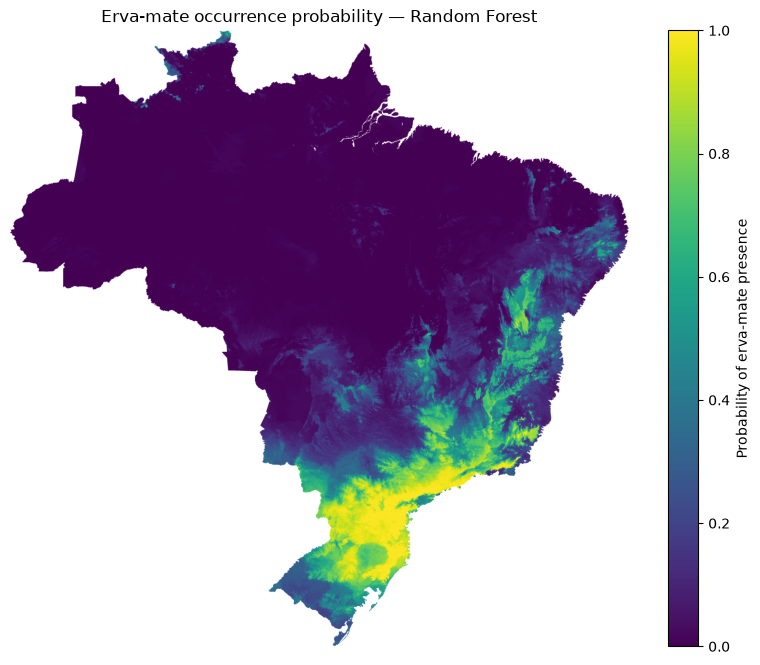

In [37]:
# Display probability of occurrence.
with rasterio.open(probability_output) as src:
    probability_map = src.read(1, masked=True)

plt.figure(figsize=(10, 8))
plt.imshow(probability_map, vmin=0, vmax=1)
plt.colorbar(label="Probability of erva-mate presence")
plt.title("Erva-mate occurrence probability — Random Forest")
plt.axis("off")
plt.show()

### 6.4 Mapa binário

Usa o limiar fixo `P(presença) ≥ 0,50`.

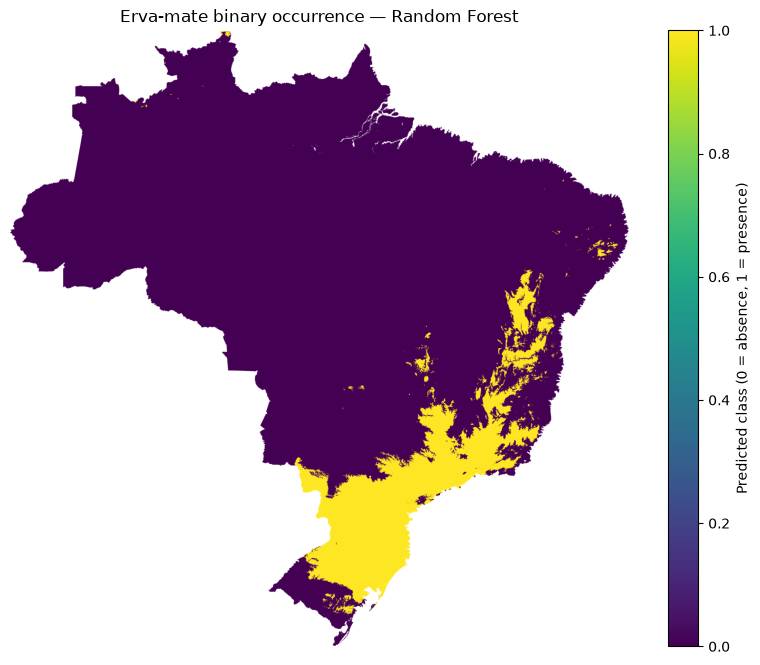

In [38]:
# Display binary occurrence prediction.
with rasterio.open(binary_output) as src:
    binary_map = src.read(1, masked=True)

plt.figure(figsize=(10, 8))
plt.imshow(binary_map, vmin=0, vmax=1)
plt.colorbar(label="Predicted class (0 = absence, 1 = presence)")
plt.title("Erva-mate binary occurrence — Random Forest")
plt.axis("off")
plt.show()

### 6.5 Checagem final da validação espacial

Confirma que nenhum bloco é compartilhado entre treino e teste, nem entre treino e validação em qualquer fold.

In [39]:
# Check train/test block separation.
assert not (
    set(train_spatial["block_id"])
    & set(test_spatial["block_id"])
)

# Check every spatial CV fold.
for train_idx, validation_idx in spatial_cv:
    assert not (
        set(train_spatial.loc[train_idx, "block_id"])
        & set(train_spatial.loc[validation_idx, "block_id"])
    )

print("FINAL CHECK PASSED")
print("- no block is shared between training and independent test")
print("- no block is shared within any spatial CV split")
print("- GridSearchCV used the predefined spatial folds")
print("- output 1: probability of presence (0–1)")
print("- output 2: binary occurrence (0/1)")

FINAL CHECK PASSED
- no block is shared between training and independent test
- no block is shared within any spatial CV split
- GridSearchCV used the predefined spatial folds
- output 1: probability of presence (0–1)
- output 2: binary occurrence (0/1)


### Leitura dos mapas

- **Área principal:** os valores altos se concentram no Paraná, em Santa Catarina, no norte do Rio Grande do Sul, no sul de São Paulo e no sul de Mato Grosso do Sul, o que coincide com a faixa de 21°S a 30°S do [estudo da Embrapa](https://www.alice.cnptia.embrapa.br/alice/bitstream/doc/300244/1/AreaDistribuicao.pdf).
- **Ao norte dessa faixa:** o mapa reflete os registros de Minas Gerais e da Bahia, com uma faixa que segue pelas serras até a Chapada Diamantina.
- **Manchas pequenas no Planalto Central, no sudoeste de Goiás, no Nordeste oriental e no extremo norte de Roraima:** só o entorno de Brasília tem presenças, então essas manchas devem ser lidas como áreas de clima parecido, não como ocorrência confirmada.
- **Áreas em branco no litoral e na foz do Amazonas:** são pixels sem dado em `HAND`, `NTSI` ou `slope` (etapa 2), além de lagoas como a dos Patos.

## 7. Resumo para o formulário

In [40]:
resumo = {
    "Pontos antes da limpeza": etapas["Baixados do GBIF"],
    "Pontos depois da limpeza": etapas["Uma presença por pixel"],
    "Pseudoausências": int((samples["presence"] == 0).sum()),
    "ROC AUC do teste espacial independente": round(roc_auc_score(y_test, prob_test), 3),
    "Melhores hiperparâmetros": grid_search.best_params_,
}
display(pd.Series(resumo))

Pontos antes da limpeza                                                              1599
Pontos depois da limpeza                                                              571
Pseudoausências                                                                       571
ROC AUC do teste espacial independente                                              0.982
Melhores hiperparâmetros                  {'max_features': 'sqrt', 'min_samples_leaf': 5}
dtype: object